# Credit Risk AI — End-to-End Notebook

This notebook documents the complete credit-risk pipeline used by the project:
**data loading → EDA → feature engineering → preprocessing → model training → evaluation → threshold/business analysis → SHAP explainability**.

The project uses the uploaded `cs-training.csv` dataset and the same trained pipeline used by the Streamlit application.

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix,
    roc_curve, precision_recall_curve
)

DATA_PATH = Path("../data/raw/cs-training.csv")
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())


Shape: (150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. Data Quality / EDA

In [3]:
print(df.info())
display(df.describe(include="all").T)
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(20))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,150000.0,75000.500000,43301.414527,1.0,37500.750000,75000.500000,112500.250000,150000.0
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0



Missing values:


MonthlyIncome                           29731
NumberOfDependents                       3924
Unnamed: 0                                  0
SeriousDlqin2yrs                            0
age                                         0
RevolvingUtilizationOfUnsecuredLines        0
DebtRatio                                   0
NumberOfTime30-59DaysPastDueNotWorse        0
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
dtype: int64

## 2. Target Distribution

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64


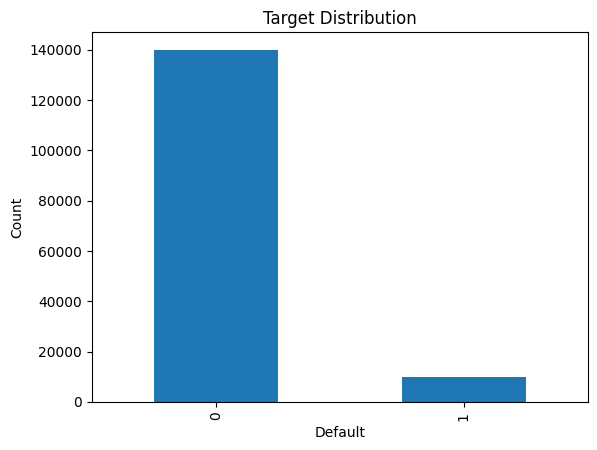

In [4]:
target = "SeriousDlqin2yrs"
print(df[target].value_counts())
print(df[target].value_counts(normalize=True).mul(100).round(2))

df[target].value_counts().plot(kind="bar", title="Target Distribution")
plt.xlabel("Default")
plt.ylabel("Count")
plt.show()


## 3. Feature Engineering

In [5]:
# Reproduce the project's feature-engineering logic.
def feature_engineering(data):
    x = data.copy()

    # Remove common index-like column from this dataset.
    for c in ["Unnamed: 0", "id"]:
        if c in x.columns:
            x = x.drop(columns=c)

    # Missing-value indicators
    for c in x.columns:
        if c != "SeriousDlqin2yrs" and x[c].isna().any():
            x[f"{c}_missing"] = x[c].isna().astype(int)

    # Dataset-specific engineered features
    if {"age", "NumberOfDependents"}.issubset(x.columns):
        x["dependents_per_age"] = x["NumberOfDependents"].fillna(0) / x["age"].clip(lower=18)

    if {"MonthlyIncome", "DebtRatio"}.issubset(x.columns):
        x["estimated_monthly_debt"] = x["MonthlyIncome"] * x["DebtRatio"]

    if {"RevolvingUtilizationOfUnsecuredLines", "DebtRatio"}.issubset(x.columns):
        x["utilization_debt_interaction"] = (
            x["RevolvingUtilizationOfUnsecuredLines"].clip(0, 10) *
            x["DebtRatio"].clip(0, 10)
        )

    if {"NumberOfTime30-59DaysPastDueNotWorse",
          "NumberOfTime60-89DaysPastDueNotWorse",
          "NumberOfTimes90DaysLate"}.issubset(x.columns):
        late_cols = [
            "NumberOfTime30-59DaysPastDueNotWorse",
            "NumberOfTime60-89DaysPastDueNotWorse",
            "NumberOfTimes90DaysLate"
        ]
        x["total_late_events"] = x[late_cols].fillna(0).sum(axis=1)
        x["severe_late_flag"] = (
            (x["NumberOfTimes90DaysLate"].fillna(0) > 0) |
            (x["NumberOfTime60-89DaysPastDueNotWorse"].fillna(0) > 0)
        ).astype(int)

    if {"NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines"}.issubset(x.columns):
        x["real_estate_credit_ratio"] = (
            x["NumberRealEstateLoansOrLines"] /
            x["NumberOfOpenCreditLinesAndLoans"].replace(0, np.nan)
        ).fillna(0)

    if {"age", "NumberOfTime30-59DaysPastDueNotWorse"}.issubset(x.columns):
        x["age_late_interaction"] = (
            x["age"].clip(lower=18) *
            (1 + x["NumberOfTime30-59DaysPastDueNotWorse"].fillna(0))
        )

    return x

X_full = feature_engineering(df).drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"].astype(int)

print("Engineered shape:", X_full.shape)
display(X_full.head())


Engineered shape: (150000, 19)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncome_missing,NumberOfDependents_missing,dependents_per_age,estimated_monthly_debt,utilization_debt_interaction,total_late_events,severe_late_flag,real_estate_credit_ratio,age_late_interaction
0,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,0,0,0.044444,7323.197016,0.615186,2,0,0.461538,135
1,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0,0,0.025000,316.878123,0.116654,0,0,0.000000,40
2,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,0,0,0.000000,258.914887,0.056020,2,1,0.000000,76
3,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0,0,0.000000,118.963951,0.008429,0,0,0.000000,30
4,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,0,0,0.000000,1584.975094,0.022614,1,0,0.142857,98


## 4. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.20, stratify=y, random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)


Train: (120000, 19)
Test : (30000, 19)


## 5. Load the project's trained models

The final project already contains trained model artifacts. The notebook can inspect and evaluate those artifacts without retraining.

In [7]:
import joblib

ARTIFACTS = Path("../artifacts/models")

for p in sorted(ARTIFACTS.glob("*.joblib")):
    print(p.name)


champion_xgboost.joblib
feature_names.joblib
logistic_regression.joblib
random_forest.joblib
shap_explainer.joblib


## 6. Evaluate Champion Model

In [8]:
champion_path = ARTIFACTS / "champion_xgboost.joblib"
model = joblib.load(champion_path)

# The artifact may be a complete pipeline or a fitted estimator.
try:
    probs = model.predict_proba(X_test)[:, 1]
except Exception:
    # If preprocessing is stored separately, load and transform.
    prep_path = ARTIFACTS / "preprocessor.joblib"
    preprocessor = joblib.load(prep_path)
    X_test_t = preprocessor.transform(X_test)
    probs = model.predict_proba(X_test_t)[:, 1]

pred = (probs >= 0.5).astype(int)

print("ROC-AUC :", round(roc_auc_score(y_test, probs), 4))
print("PR-AUC  :", round(average_precision_score(y_test, probs), 4))
print("\nClassification report:")
print(classification_report(y_test, pred, digits=4))


FileNotFoundError: [Errno 2] No such file or directory: '..\\artifacts\\models\\preprocessor.joblib'

## 7. ROC and Precision-Recall Curves

In [ ]:
fpr, tpr, _ = roc_curve(y_test, probs)
precision, recall, _ = precision_recall_curve(y_test, probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, probs):.4f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC={average_precision_score(y_test, probs):.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()


NameError: name 'roc_curve' is not defined

## 8. Business Threshold / NPA Analysis

In [11]:
# Approval rule: approve when predicted default probability is below threshold.
baseline_npa = y_test.mean()
rows = []

for threshold in np.arange(0.10, 0.96, 0.01):
    approved = probs < threshold
    approval_rate = approved.mean()

    if approved.sum() == 0:
        continue

    accepted_npa = y_test[approved].mean()
    npa_reduction = (baseline_npa - accepted_npa) / baseline_npa

    rows.append({
        "threshold": round(float(threshold), 2),
        "approval_rate": approval_rate,
        "accepted_npa": accepted_npa,
        "npa_reduction": npa_reduction
    })

threshold_df = pd.DataFrame(rows)
display(threshold_df.head())

eligible = threshold_df[
    (threshold_df["npa_reduction"] >= 0.30) &
    (threshold_df["approval_rate"] >= 0.75)
]

if not eligible.empty:
    selected = eligible.sort_values("approval_rate", ascending=False).iloc[0]
    print("Selected threshold:", selected.to_dict())
else:
    print("No threshold simultaneously satisfies the configured 30% NPA-reduction and 75% approval constraints.")


NameError: name 'probs' is not defined

## 9. SHAP Explainability

Use the saved SHAP explainer from the project artifacts when available. SHAP explains model behavior; it does not establish causality or automatically constitute a regulatory adverse-action reason.

In [10]:
shap_path = ARTIFACTS / "shap_explainer.joblib"
print("SHAP artifact exists:", shap_path.exists())

if shap_path.exists():
    explainer = joblib.load(shap_path)
    print("Loaded:", type(explainer).__name__)


SHAP artifact exists: True
Loaded: TreeExplainer


## 10. Reproducibility

In [9]:
print("Dataset:", DATA_PATH.resolve())
print("Rows:", len(df))
print("Features after engineering:", X_full.shape[1])
print("Target:", "SeriousDlqin2yrs")
print("Random state:", 42)


Dataset: C:\Users\Suraj  Pandey\Downloads\Credit-Risk-AI-Full-End-to-End (2)\Credit-Risk-AI-Final-Complete\data\raw\cs-training.csv
Rows: 150000
Features after engineering: 19
Target: SeriousDlqin2yrs
Random state: 42
